# One-stage anchor-based detection: RetinaNet on VisDrone

This notebook evaluates a one-stage anchor-based detector and studies the effects of anchor design, loss configuration, and inference settings on aerial object detection.

| Analysis | Section |
|---|---|
| Class distribution, object sizes, scene density, and sequence variation | §1 |
| Sequence-level separation, frame subsampling, and preprocessing | §1–§2 |
| Data-driven anchor configurations | §3 |
| Model variants and evaluation protocol | §4–§6 |
| mAP, AP50, AP by object size, and inference speed | §4, §7 |
| Anchor matching and foreground/background imbalance | §8–§9 |
| One-stage and two-stage comparison | §10 |
| Detection error analysis | §11 |

**Evaluation protocol.** COCO evaluation uses every fifth validation frame, up to 500 detections per image, and ignored regions marked as `iscrowd`. Inference speed is measured with batch size 1.

**Evaluated checkpoints.** The models are loaded from Hugging Face without additional training by default: RetinaNet baseline (step 5, 12 epochs), RetinaNet with smaller anchors (step 5, 12 epochs), RetinaNet with smaller anchors and focal α = 0.5 (step 20, 6 epochs), and Faster R-CNN (step 20, 6 epochs). The original baseline's sampling protocol is based on existing experiment records rather than checkpoint metadata. Comparisons between models with different training budgets are reported as observational rather than controlled ablations.


## 0. Environment and configuration

The setup defines dataset paths, checkpoint locations, evaluation settings, and the random seed. `SMOKE` enables a reduced test run before a full evaluation.


In [1]:
import os, sys, json, time, math, random, re, io, types, shutil, threading, subprocess, contextlib, warnings
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

# ======================= CONFIG =======================
SMOKE = False                      # True: tiny end-to-end test run
SEED = 42
TRAIN_STEP, VAL_STEP = (5, 5) if not SMOKE else (100, 100)
EPOCHS = 12 if not SMOKE else 1
MIN_SIZE, MAX_SIZE = 640, 1280
BATCH, LR, LR_SCHEDULE, WORKERS = 1, 1e-3, "step", 2
SELECT_BY = "mAP"                  # metric used to pick the winner of each tuning stage

ON_KAGGLE = Path("/kaggle/working").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("work")
WORK.mkdir(exist_ok=True)
SUFFIX = "_smoke" if SMOKE else ""
RUNS = WORK / f"runs_one_stage{SUFFIX}"
RESULTS_PATH = WORK / f"one_stage_results{SUFFIX}.json"

# --- dataset ---
_cands = [Path(os.environ["PIPELINE_DATA_ROOT"])] if "PIPELINE_DATA_ROOT" in os.environ else []
_cands += [Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026"),
           Path("/kaggle/input/multiple-object-video-detection-hw-2-ucu-ai-2026"), Path("/content/data")]
DATA_ROOT = next((p for p in _cands if (p / "train" / "annotations_coco.json").is_file()), None)
if DATA_ROOT is None and Path("/kaggle/input").exists():
    _found = sorted(Path("/kaggle/input").glob("**/train/annotations_coco.json"))
    if len(_found) == 1:
        DATA_ROOT = _found[0].parent.parent
    elif len(_found) > 1:
        raise RuntimeError("Multiple datasets found: " + str([str(p.parent.parent) for p in _found]) +
                           ". Set PIPELINE_DATA_ROOT to the intended dataset root.")
if DATA_ROOT is None:
    available = [str(p) for p in Path("/kaggle/input").iterdir()] if Path("/kaggle/input").exists() else []
    raise FileNotFoundError(
        "VisDrone dataset is not attached (or has a different layout). "
        "In Kaggle edit mode, use Add Input to attach the competition dataset. "
        "Expected train/annotations_coco.json and val/annotations_coco.json. "
        f"Available /kaggle/input entries: {available}. "
        "If mounted elsewhere, set PIPELINE_DATA_ROOT to its root."
    )
if not (DATA_ROOT / "val" / "annotations_coco.json").is_file():
    raise FileNotFoundError(f"Validation COCO annotations missing under {DATA_ROOT / 'val'}")
TRAIN_COCO, VAL_COCO = DATA_ROOT / "train" / "annotations_coco.json", DATA_ROOT / "val" / "annotations_coco.json"

# --- ready checkpoints on Hugging Face: every model is evaluated from a checkpoint, nothing is trained by default ---
HF_REPO = "lilialania/visdrone-retinanet"
CHECKPOINTS = {
    "retinanet_baseline": "checkpoints/epoch_12.pt",
    "retinanet_small_anchors": "small_anchors/epoch_12.pt",
    "retinanet_focal_alpha05": "focal_alpha05_step20/epoch_06.pt",
    "faster_rcnn": "faster_rcnn_step20/epoch_06.pt",
}
# build_retinanet overrides that reproduce each checkpoint's ANCHORS at inference (anchors have no weights; loss settings do not matter for inference)
INFER_CFG = {"retinanet_baseline": {}, "retinanet_small_anchors": {"base": 16}, "retinanet_focal_alpha05": {"base": 16}}
# training budget of each checkpoint - the models were NOT all trained under one identical protocol; state this in the report
BUDGET = {"retinanet_baseline": "step5 / 12 ep (assumed)", "retinanet_small_anchors": "step5 / 12 ep",
          "retinanet_focal_alpha05": "step20 / 6 ep (small anchors + focal alpha 0.5)", "faster_rcnn": "step20 / 6 ep"}
RUN_EXTRA_TRAINING = False         # True: additionally train extra one-stage variants in section 6b (data-driven anchors, IoU thresholds, box loss)

# --- evaluation protocol shared with the query-based evaluation notebook ---
EVAL_DETS = 500                    # detections per image at evaluation = Kaggle cap (MAX_DETECTIONS); the model default of 300 is only a training-time setting
# --- Hugging Face persistence (Kaggle /working is wiped between sessions); token comes from Kaggle Secrets, as in the evaluation notebook ---
HF_PREFIX = "one_stage_anchor_based_step5"      # folder in HF_REPO for this notebook's checkpoints / results
UPLOAD_TO_HF = True
print("data:", DATA_ROOT, "| work:", WORK, "| smoke:", SMOKE)

data: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026 | work: /kaggle/working | smoke: False


In [2]:
REPO_URL = "https://github.com/lilialania/drone-multi-object-detection.git"
REPO_DIR = WORK / "drone-multi-object-detection"
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
sys.path.insert(0, str(REPO_DIR))

import torch, torchvision
# The repository reorganized dataset utilities into src/data/.
# Resolve imports explicitly instead of silently hiding a broken dependency.
from src.data import data_utils as du
from src.data.make_subset import _annotation_path
print("Data module:", du.__file__)
from src.models.yolo_baseline import MAX_DETECTIONS
from src.models.faster_rcnn import YoloDetectionDataset, train as repo_train, load_trained as repo_load_trained   # repo_load_trained: Faster R-CNN only
from src.models.retinanet import build_model as build_baseline      # the exact baseline builder from src/models/retinanet.py

CLASS_NAMES = du.CLASS_NAMES
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
commit = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | repo commit {commit} | device {DEVICE}",
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

# ---- Hugging Face helpers (same repo/token mechanism as the evaluation notebook) ----
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub", "pycocotools"], check=False)
from huggingface_hub import HfApi, hf_hub_download

def get_hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN").strip()
    except Exception:
        return os.environ.get("HF_TOKEN")

HF_TOKEN = get_hf_token()
API = HfApi(token=HF_TOKEN) if HF_TOKEN else None
try:
    REMOTE = set(API.list_repo_files(repo_id=HF_REPO, repo_type="model", token=HF_TOKEN)) if API else set()
except Exception as e:
    print("HF not reachable:", repr(e)[:120]); REMOTE = set()
print("HF:", "connected, %d files in %s" % (len(REMOTE), HF_REPO) if REMOTE else "not available (no token) - local files only")

def hf_download(remote, local_dir):
    """Download `remote` from HF_REPO into local_dir (keeps the remote sub-path); None if it does not exist."""
    if remote not in REMOTE: return None
    return Path(hf_hub_download(repo_id=HF_REPO, filename=remote, repo_type="model", token=HF_TOKEN, local_dir=str(local_dir)))

def hf_upload(path, remote):
    if UPLOAD_TO_HF and API and not SMOKE:
        API.upload_file(path_or_fileobj=str(path), path_in_repo=remote, repo_id=HF_REPO, repo_type="model", token=HF_TOKEN)

Cloning into '/kaggle/working/drone-multi-object-detection'...


Data module: /kaggle/working/drone-multi-object-detection/src/data/data_utils.py
torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | repo commit 2507752 | device cuda Tesla T4
HF: connected, 150 files in lilialania/visdrone-retinanet


## 1. Dataset analysis

The analysis covers class frequencies, bounding-box sizes before and after resizing to 640/1280, the number of objects per frame, and variation across video sequences. These measurements inform anchor scales, aspect ratios, and the maximum number of detections per image.


In [3]:
tr_imgs, tr_ann = du.load_coco(TRAIN_COCO, "train")
va_imgs, va_ann = du.load_coco(VAL_COCO, "val")
tr_t, tr_ign = du.split_annotations(tr_ann)      # targets (iscrowd=0) vs ignored regions (iscrowd=1)
va_t, va_ign = du.split_annotations(va_ann)

# split is by sequence: no clip may appear in both train and val
shared = set(tr_imgs["clip"]) & set(va_imgs["clip"])
assert not shared, f"clips shared between train and val: {sorted(shared)[:5]}"

overview = pd.DataFrame({
    "frames": [len(tr_imgs), len(va_imgs)], "clips": [tr_imgs["clip"].nunique(), va_imgs["clip"].nunique()],
    "target boxes": [len(tr_t), len(va_t)], "ignored regions": [len(tr_ign), len(va_ign)],
}, index=["train", "val"])
display(overview)
print("image sizes (train):", tr_imgs[["width", "height"]].value_counts().head(3).to_dict())

# conversion check: YOLO label/ignore files must match the COCO boxes
for split, path in (("train", TRAIN_COCO), ("val", VAL_COCO)):
    print(split, du.check_yolo_consistency(path, DATA_ROOT / split, split, 50, SEED))

,frames,clips,target boxes,ignored regions
train,24201,56,1105516,63843
val,2846,7,114132,3995


image sizes (train): {(1904, 1071): 12895, (1344, 756): 5645, (2688, 1512): 3505}
train {'sampled_frames': 50, 'target_boxes_compared': 2043, 'ignored_regions_compared': 182, 'ignored_duplicates_removed': 446901}
val {'sampled_frames': 50, 'target_boxes_compared': 2266, 'ignored_regions_compared': 69, 'ignored_duplicates_removed': 27965}


In [4]:
def gt_table(ann):
    """One row per target box with original and post-resize sizes (torchvision resize: min side->640, max side<=1280)."""
    d = du.add_box_dimensions(ann)                      # box_w, box_h, area, sqrt_area, class_name
    xywh = np.asarray(d["bbox"].tolist(), float)
    d = d.assign(x=xywh[:, 0], y=xywh[:, 1])
    d["scale"] = np.minimum(MIN_SIZE / np.minimum(d["width"], d["height"]), MAX_SIZE / np.maximum(d["width"], d["height"]))
    d["rs_sqrt"] = d["sqrt_area"] * d["scale"]          # sqrt(area) as the network sees it
    d["hw"] = d["box_h"] / d["box_w"]                   # torchvision's "aspect ratio" convention (h / w)
    d["bucket"] = pd.cut(d["area"], [-np.inf, 32**2, 96**2, np.inf], labels=["small", "medium", "large"], right=False)
    return d

G_tr, G_va = gt_table(tr_t), gt_table(va_t)
dens_tr, per_clip_tr, dens_stats = du.density_summary(tr_imgs, tr_t)
dens_va, _, _ = du.density_summary(va_imgs, va_t)

cls = pd.concat([G_tr["class_name"].value_counts().rename("train"), G_va["class_name"].value_counts().rename("val")], axis=1).reindex(CLASS_NAMES)
cls["train %"] = 100 * cls["train"] / cls["train"].sum(); cls["val %"] = 100 * cls["val"] / cls["val"].sum()
display(cls.round(2))
print("COCO size buckets, train (% of boxes):", (100 * G_tr["bucket"].value_counts(normalize=True)).round(1).to_dict())
print("COCO size buckets, val   (% of boxes):", (100 * G_va["bucket"].value_counts(normalize=True)).round(1).to_dict())
print("sqrt(area) quantiles after resize [5,25,50,75,95,99]:", np.quantile(G_tr["rs_sqrt"], [.05, .25, .5, .75, .95, .99]).round(1))
print("objects/frame train: mean %.1f | median %d | p99 %d | max %d" % (dens_tr.objects.mean(), dens_tr.objects.median(), dens_stats["p99_objects_per_frame"], dens_stats["max_objects_per_frame"]))
print("objects/frame val  : mean %.1f | max %d" % (dens_va.objects.mean(), dens_va.objects.max()))
print("ignored regions per frame (train): %.2f" % (len(tr_ign) / len(tr_imgs)))
print("h/w quantiles [5,25,50,75,95]:", np.quantile(G_tr["hw"], [.05, .25, .5, .75, .95]).round(2))

,train,val,train %,val %
class_name,,,,
person,328701,50312,29.73,44.08
bicycle,40255,6022,3.64,5.28
car,505301,31821,45.71,27.88
van,46940,6842,4.25,5.99
truck,30498,1359,2.76,1.19
tricycle,41349,5487,3.74,4.81
bus,9653,264,0.87,0.23
motor,102819,12025,9.30,10.54


COCO size buckets, train (% of boxes): {'medium': 63.5, 'small': 24.9, 'large': 11.6}
COCO size buckets, val   (% of boxes): {'medium': 69.5, 'small': 19.2, 'large': 11.3}
sqrt(area) quantiles after resize [5,25,50,75,95,99]: [ 12.1  19.2  27.   39.   74.3 115. ]
objects/frame train: mean 45.7 | median 43 | p99 142 | max 180
objects/frame val  : mean 40.1 | max 116
ignored regions per frame (train): 2.64
h/w quantiles [5,25,50,75,95]: [0.41 0.69 1.06 1.69 2.55]


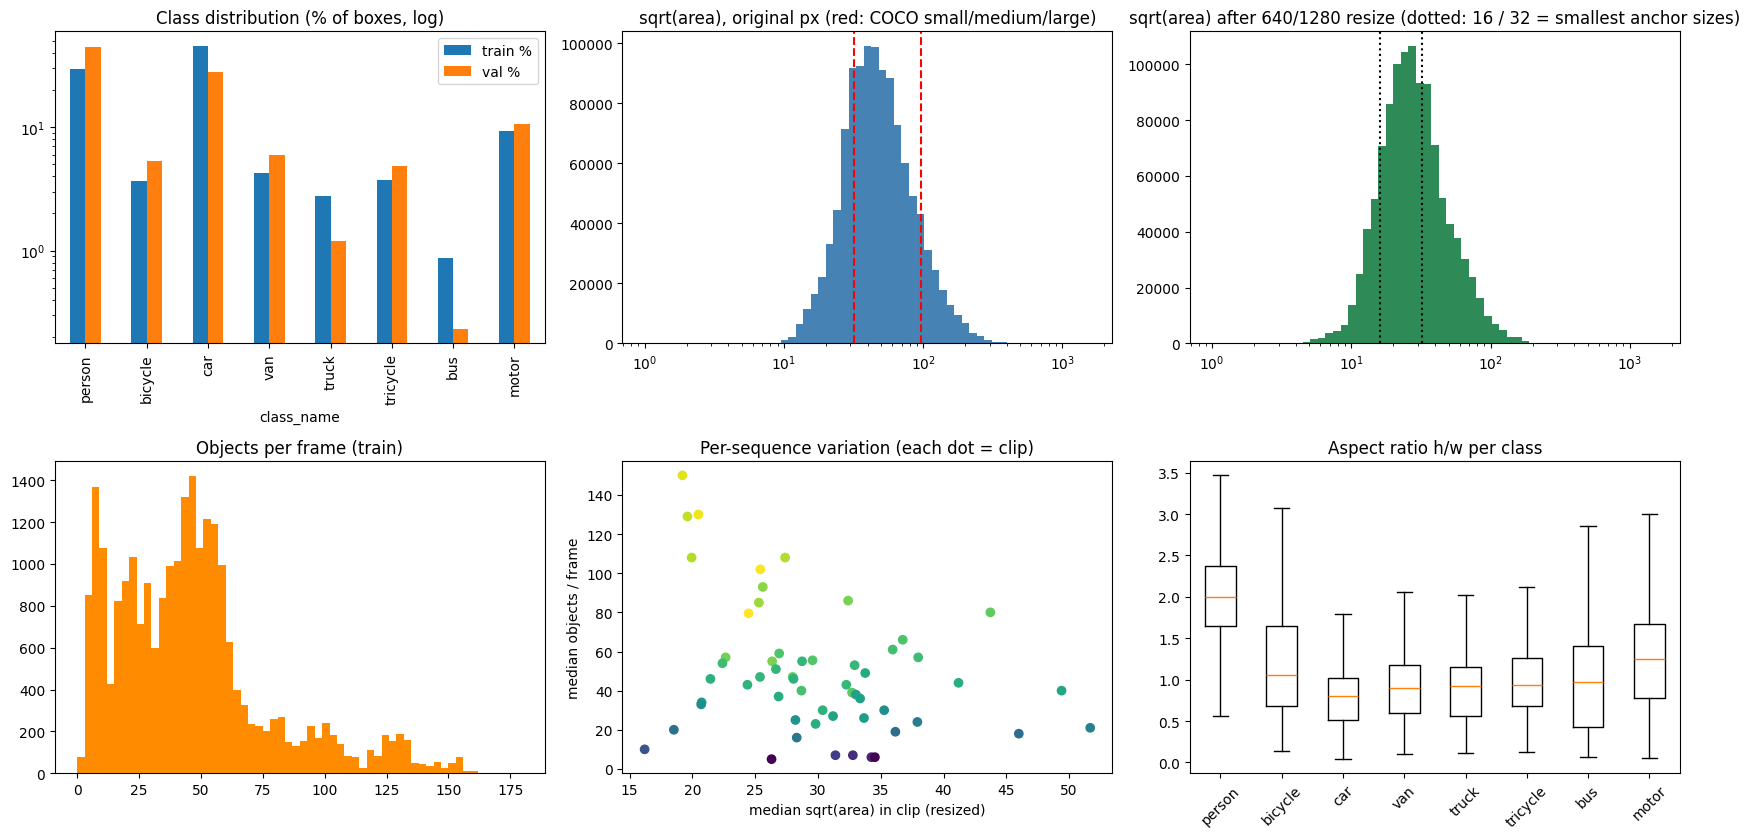

,med_size,boxes,med_objs,max_objs
min,16.2,706.0,5.0,7.0
50%,28.7,16044.5,43.5,59.5
max,51.7,64916.0,150.0,180.0


In [5]:
clip_stats = G_tr.groupby("clip").agg(med_size=("rs_sqrt", "median"), boxes=("rs_sqrt", "size"))
clip_stats = clip_stats.join(per_clip_tr.set_index("clip")[["median", "max"]].rename(columns={"median": "med_objs", "max": "max_objs"}))

fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
cls[["train %", "val %"]].plot.bar(ax=ax[0, 0], logy=True, title="Class distribution (% of boxes, log)")
bins = np.logspace(0, 3.2, 60)
ax[0, 1].hist(G_tr["sqrt_area"], bins=bins, color="steelblue"); ax[0, 1].set_xscale("log")
ax[0, 1].axvline(32, c="r", ls="--"); ax[0, 1].axvline(96, c="r", ls="--"); ax[0, 1].set_title("sqrt(area), original px (red: COCO small/medium/large)")
ax[0, 2].hist(G_tr["rs_sqrt"], bins=bins, color="seagreen"); ax[0, 2].set_xscale("log")
for s in (16, 32): ax[0, 2].axvline(s, c="k", ls=":")
ax[0, 2].set_title("sqrt(area) after 640/1280 resize (dotted: 16 / 32 = smallest anchor sizes)")
ax[1, 0].hist(dens_tr["objects"], bins=60, color="darkorange"); ax[1, 0].set_title("Objects per frame (train)")
ax[1, 1].scatter(clip_stats["med_size"], clip_stats["med_objs"], c=np.log1p(clip_stats["max_objs"]), cmap="viridis")
ax[1, 1].set_xlabel("median sqrt(area) in clip (resized)"); ax[1, 1].set_ylabel("median objects / frame"); ax[1, 1].set_title("Per-sequence variation (each dot = clip)")
ax[1, 2].boxplot([G_tr.loc[G_tr.class_name == c, "hw"] for c in CLASS_NAMES], labels=CLASS_NAMES, showfliers=False)
ax[1, 2].set_title("Aspect ratio h/w per class"); ax[1, 2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
display(clip_stats.describe().loc[["min", "50%", "max"]].round(1))

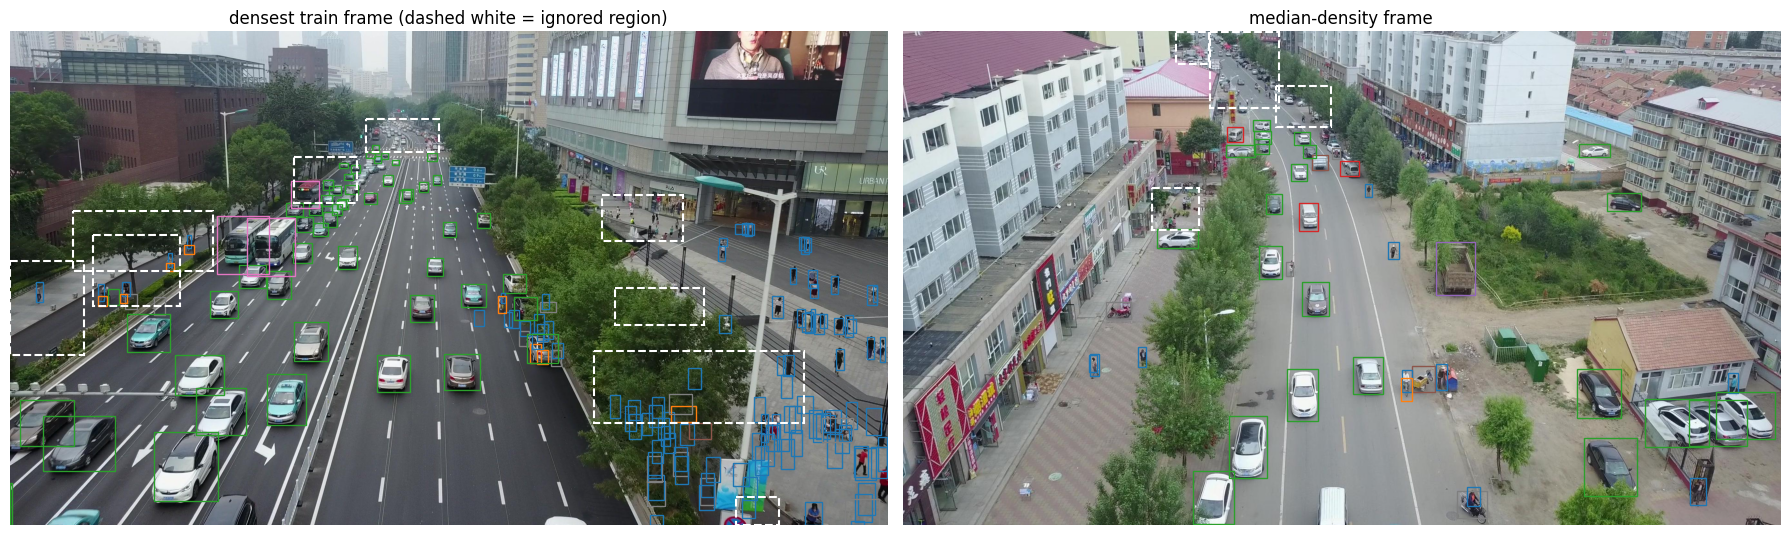

In [6]:
from PIL import Image
import matplotlib.patches as patches

def draw_gt(ax, image_id, images_df, targets, ignored, split_root, title=""):
    fn = images_df.set_index("id").loc[image_id, "file_name"]
    ax.imshow(Image.open(du.image_path_for(split_root, fn))); ax.axis("off"); ax.set_title(title)
    palette = plt.get_cmap("tab10")
    for r in targets[targets["image_id"] == image_id].itertuples():
        x, y, w, h = r.bbox
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec=palette(int(r.category_id) - 1), lw=1))
    for r in ignored[ignored["image_id"] == image_id].itertuples():
        x, y, w, h = r.bbox
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="white", ls="--", lw=1.5))

dense_id = int(dens_tr.loc[dens_tr["objects"].idxmax(), "id"])
mid_id = int(dens_tr.iloc[(dens_tr["objects"] - dens_tr["objects"].median()).abs().argsort().iloc[0]]["id"])
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
draw_gt(ax[0], dense_id, tr_imgs, tr_t, tr_ign, DATA_ROOT / "train", "densest train frame (dashed white = ignored region)")
draw_gt(ax[1], mid_id, tr_imgs, tr_t, tr_ign, DATA_ROOT / "train", "median-density frame")
plt.tight_layout(); plt.show()

### Dataset characteristics relevant to detection

- **Class frequencies:** class imbalance can affect per-class average precision.
- **Object sizes:** the resized `sqrt(area)` quantiles and the proportion of boxes smaller than 32 pixels provide a reference for the smallest anchor scale.
- **Aspect ratios:** differences between pedestrian and vehicle shapes motivate evaluating more than one ratio configuration.
- **Scene density:** high object counts motivate a sufficiently large `detections_per_img` limit.
- **Sequence variation:** the distribution of objects and box sizes differs across clips, creating variability within a single global detector configuration.
- **Ignored regions:** these regions are omitted from training labels and handled as `iscrowd` during evaluation.


## 2. Training subset and temporal subsampling

Every `TRAIN_STEP`-th frame is sampled separately within each video clip, maintaining representation of all sequences. The training subset is arranged in the directory structure expected by the training code. Sampling every fifth frame reduces redundancy between neighboring images and lowers the training workload. Training and validation sequences are disjoint; validation uses every `VAL_STEP`-th frame.


In [7]:
SUBSET = WORK / f"visdrone-step{TRAIN_STEP}"

def make_symlink_subset(images, split, step, out):
    split_root = DATA_ROOT / split
    frames = du.subsampled_frame_list(images, step)          # every step-th frame inside each clip
    for it in frames:
        src = du.image_path_for(split_root, it["file_name"])
        src_lbl = _annotation_path(split_root, it["file_name"], "labels")
        clip = str(it["clip"])
        for s, d in ((src, out / split / "images" / clip / src.name), (src_lbl, out / split / "labels" / clip / (src.stem + ".txt"))):
            if s.exists() and not d.exists():
                d.parent.mkdir(parents=True, exist_ok=True); os.symlink(s.resolve(), d)
    return len(frames)

N_TRAIN = make_symlink_subset(tr_imgs, "train", TRAIN_STEP, SUBSET)
(SUBSET / "val" / "images").mkdir(parents=True, exist_ok=True)   # train() only needs the folder to exist
n_img = len(list((SUBSET / "train" / "images").rglob("*.jpg"))); n_lbl = len(list((SUBSET / "train" / "labels").rglob("*.txt")))
print(f"train subset: {N_TRAIN} frames (of {len(tr_imgs)}), images on disk {n_img}, label files {n_lbl}, clips {tr_imgs['clip'].nunique()}")

train subset: 4868 frames (of 24201), images on disk 4868, label files 4868, clips 56


## 3. Anchor configuration based on object sizes

RetinaNet assigns positive anchors at IoU ≥ 0.5, negative anchors below IoU 0.4, and ignores anchors in between. Low-quality matching also preserves a best-match anchor for each ground-truth box.

Candidate configurations are evaluated using the best anchor-to-ground-truth IoU after resizing. Anchor coverage is calculated using grid positions from the feature pyramid (strides 8–128), with base sizes of 8, 12, 16, 20, 24, or 32 pixels and several aspect-ratio sets.

Each configuration maintains three scales and three aspect ratios per location, preserving nine anchors per location and the checkpoint-compatible regression-head dimensions. Coverage is a geometric diagnostic; detection quality is measured separately using COCO metrics.


In [8]:
STRIDES = (8, 16, 32, 64, 128)                      # RetinaNet P3..P7 in torchvision

def level_sizes(base):
    """torchvision's rule: per level (x, x*2^(1/3), x*2^(2/3)) with x = base * 2^level. base=32 reproduces the default."""
    return tuple((int(x), int(x * 2 ** (1 / 3)), int(x * 2 ** (2 / 3))) for x in (base * 2 ** l for l in range(5)))

def anchor_wh(sizes, ratios):
    r = np.sqrt(np.asarray(ratios, float)); s = np.asarray(sizes, float)       # ratio = h / w
    ws = ((1 / r)[:, None] * s[None]).ravel(); hs = (r[:, None] * s[None]).ravel()
    return np.stack([np.round(ws / 2) * 2, np.round(hs / 2) * 2], 1)

def best_iou_stats(gt, sizes_per_level, ratios, thr=0.5):
    """gt: [N,4] xyxy in resized pixels. Best IoU over anchors on the 4 nearest grid points of every level."""
    cx, cy = (gt[:, 0] + gt[:, 2]) / 2, (gt[:, 1] + gt[:, 3]) / 2
    garea = (gt[:, 2] - gt[:, 0]) * (gt[:, 3] - gt[:, 1])
    best, npos = np.zeros(len(gt)), np.zeros(len(gt))
    for stride, sizes in zip(STRIDES, sizes_per_level):
        wh = anchor_wh(sizes, ratios); aw, ah = wh[:, 0][None], wh[:, 1][None]
        for dx in (0, 1):
            for dy in (0, 1):
                ax_ = ((np.floor(cx / stride) + dx) * stride)[:, None]; ay_ = ((np.floor(cy / stride) + dy) * stride)[:, None]
                iw = np.clip(np.minimum(gt[:, 2:3], ax_ + aw / 2) - np.maximum(gt[:, 0:1], ax_ - aw / 2), 0, None)
                ih = np.clip(np.minimum(gt[:, 3:4], ay_ + ah / 2) - np.maximum(gt[:, 1:2], ay_ - ah / 2), 0, None)
                inter = iw * ih
                iou = inter / (garea[:, None] + aw * ah - inter)
                best = np.maximum(best, iou.max(1)); npos += (iou >= thr).sum(1)
    return best, npos

rng = np.random.default_rng(SEED)
idx = rng.choice(len(G_tr), size=min(40000, len(G_tr)), replace=False)
S = G_tr.iloc[idx]
GT_XYXY = np.c_[S["x"], S["y"], S["x"] + S["box_w"], S["y"] + S["box_h"]] * S["scale"].to_numpy()[:, None]
BUCKET = S["bucket"].to_numpy()

HW_Q = tuple(float(v) for v in np.round(np.quantile(G_tr["hw"], [.15, .5, .85]), 2))
RATIO_SETS = {"default (0.5,1,2)": (0.5, 1.0, 2.0), "wide (0.4,1,2.5)": (0.4, 1.0, 2.5), f"data q15/50/85 {HW_Q}": HW_Q}

def coverage_row(base, ratios, label):
    best, npos = best_iou_stats(GT_XYXY, level_sizes(base), ratios)
    row = dict(base=base, ratios=label, ratio_vals=ratios, iou50_all=(best >= .5).mean(), mean_best_iou=best.mean(), pos_anchors_per_gt=npos.mean())
    for b in ("small", "medium", "large"): row[f"iou50_{b}"] = (best[BUCKET == b] >= .5).mean()
    return row

cov = pd.DataFrame([coverage_row(b, r, n) for b in (8, 12, 16, 20, 24, 32) for n, r in RATIO_SETS.items()])
cov = cov.sort_values(["iou50_all", "mean_best_iou"], ascending=False).reset_index(drop=True)
display(cov.drop(columns="ratio_vals").head(12).round(3))
top = cov.iloc[0]
DATA_BASE, DATA_RATIOS = int(top["base"]), tuple(top["ratio_vals"])
NWD_C = float(G_tr["rs_sqrt"].mean())              # NWD normalising constant = mean object size (resized), see §4
print(f"selected data-driven anchors: base={DATA_BASE}, ratios={DATA_RATIOS}\n  sizes per level: {level_sizes(DATA_BASE)}\n  NWD constant C={NWD_C:.1f}")

,base,ratios,iou50_all,mean_best_iou,pos_anchors_per_gt,iou50_small,iou50_medium,iou50_large
0,16,"default (0.5,1,2)",0.925,0.650,5.918,0.731,0.988,0.996
1,16,"data q15/50/85 (0.53, 1.06, 2.04)",0.924,0.650,6.013,0.731,0.988,0.994
2,16,"wide (0.4,1,2.5)",0.915,0.639,4.843,0.711,0.981,0.994
3,12,"data q15/50/85 (0.53, 1.06, 2.04)",0.890,0.620,3.875,0.783,0.927,0.917
4,12,"default (0.5,1,2)",0.888,0.621,3.884,0.780,0.924,0.919
5,20,"default (0.5,1,2)",0.884,0.656,7.517,0.576,0.983,0.999
6,20,"data q15/50/85 (0.53, 1.06, 2.04)",0.884,0.655,7.605,0.576,0.983,0.998
7,12,"wide (0.4,1,2.5)",0.881,0.614,3.335,0.771,0.919,0.907
8,20,"wide (0.4,1,2.5)",0.876,0.645,6.198,0.557,0.979,0.999
9,24,"default (0.5,1,2)",0.818,0.640,8.189,0.394,0.951,0.999


selected data-driven anchors: base=16, ratios=(0.5, 1.0, 2.0)
  sizes per level: ((16, 20, 25), (32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406))
  NWD constant C=32.8


,iou50_small,iou50_medium,iou50_large,iou50_all,mean_best_iou,pos_anchors_per_gt
"baseline (32, default ratios)",0.124,0.767,0.999,0.634,0.562,7.628
"small (16, default ratios)",0.731,0.988,0.996,0.925,0.650,5.918
"data-driven (16, (0.5, 1.0, 2.0))",0.731,0.988,0.996,0.925,0.650,5.918


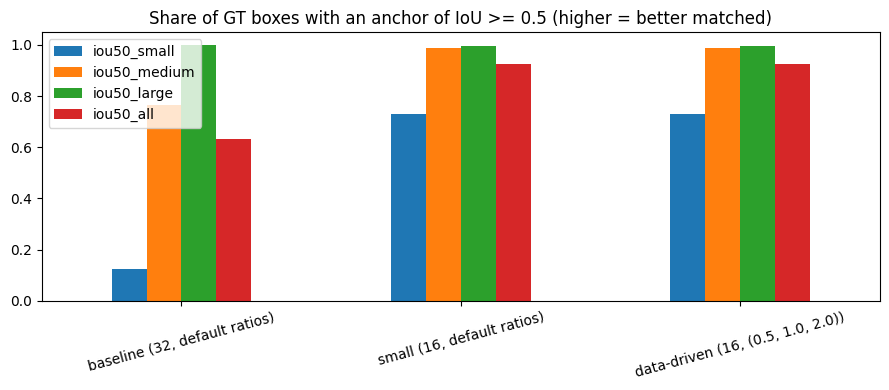

In [9]:
compare = pd.DataFrame({
    "baseline (32, default ratios)": coverage_row(32, (0.5, 1.0, 2.0), "d"),
    "small (16, default ratios)":    coverage_row(16, (0.5, 1.0, 2.0), "d"),
    f"data-driven ({DATA_BASE}, {DATA_RATIOS})": coverage_row(DATA_BASE, DATA_RATIOS, "x"),
}).T[["iou50_small", "iou50_medium", "iou50_large", "iou50_all", "mean_best_iou", "pos_anchors_per_gt"]].astype(float)
display(compare.round(3))
compare[["iou50_small", "iou50_medium", "iou50_large", "iou50_all"]].plot.bar(figsize=(9, 4), rot=15, title="Share of GT boxes with an anchor of IoU >= 0.5 (higher = better matched)")
plt.tight_layout(); plt.show()

## 4. Detector architecture, losses, and evaluation

The RetinaNet construction uses `src.models.retinanet.build_model`, based on `torchvision` RetinaNet with a ResNet-50 FPN backbone. The classification head is configured for eight foreground classes and background. Variants use the same model family with changes to the parameters below.

| Parameter | Configuration argument | Default |
|---|---|---|
| Anchor scales and ratios | `base`, `ratios` | 32, (0.5, 1, 2) |
| IoU assignment | `fg_iou`, `bg_iou` | 0.5 / 0.4 |
| Focal loss | `focal_alpha`, `focal_gamma` | 0.25 / 2.0 |
| Box regression | `box_loss` | Builder default; alternatives include L1, Smooth L1, GIoU, DIoU, CIoU, NWD, and GIoU+NWD |
| Inference | `score_thresh`, `nms_thresh`, `topk`, `dets` | 0.05 / 0.5 / 1000 / 300; evaluation uses 500 detections |

Normalized Wasserstein Distance (NWD) models boxes as two-dimensional Gaussians and uses a scale-normalized distance between them. It provides a smoother localization signal for small boxes than a purely IoU-based comparison when small coordinate shifts produce large relative overlap changes.


In [10]:
from torchvision.models.detection import _utils as det_utils
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.ops import sigmoid_focal_loss, generalized_box_iou_loss

def make_focal_loss(alpha, gamma):
    def compute_loss(self, targets, head_outputs, matched_idxs):          # mirrors torchvision, only alpha/gamma differ
        losses = []
        for target, logits, matched in zip(targets, head_outputs["cls_logits"], matched_idxs):
            fg = matched >= 0
            gt = torch.zeros_like(logits)
            gt[fg, target["labels"][matched[fg]]] = 1.0
            valid = matched != self.BETWEEN_THRESHOLDS                    # anchors in the 0.4-0.5 gap are ignored
            loss = sigmoid_focal_loss(logits[valid].float(), gt[valid].float(), alpha=alpha, gamma=gamma, reduction="sum")
            losses.append(loss / fg.sum().clamp(min=1))
        return sum(losses) / len(targets)
    return compute_loss

def nwd_loss(pred, target, c):
    pc, tc = (pred[:, :2] + pred[:, 2:]) / 2, (target[:, :2] + target[:, 2:]) / 2
    pwh, twh = pred[:, 2:] - pred[:, :2], target[:, 2:] - target[:, :2]
    w2 = ((pc - tc) ** 2).sum(1) + (((pwh - twh) / 2) ** 2).sum(1)       # squared 2-Wasserstein distance of the Gaussians
    return 1 - torch.exp(-torch.sqrt(w2 + 1e-7) / c)

def make_box_loss(kind, c):
    def compute_loss(self, targets, head_outputs, anchors, matched_idxs):  # mirrors torchvision's regression-head loss
        losses = []
        for t, reg, anc, m in zip(targets, head_outputs["bbox_regression"], anchors, matched_idxs):
            fg = torch.where(m >= 0)[0]
            if fg.numel() == 0:
                losses.append(reg.sum() * 0); continue
            gt = t["boxes"][m[fg]].float()
            pred = self.box_coder.decode_single(reg[fg].float(), anc[fg].float())
            loss = 0.0
            if "giou" in kind: loss = loss + generalized_box_iou_loss(pred, gt, reduction="sum")
            if "nwd" in kind:  loss = loss + nwd_loss(pred, gt, c).sum()
            losses.append(loss / max(1, fg.numel()))
        return sum(losses) / max(1, len(targets))
    return compute_loss

def build_retinanet(min_size, max_size, pretrained=True, base=32, ratios=(0.5, 1.0, 2.0), fg_iou=0.5, bg_iou=0.4,
                    focal_alpha=0.25, focal_gamma=2.0, box_loss=None, nwd_c=None,
                    score_thresh=0.05, nms_thresh=0.5, topk=1000, dets=300):
    assert len(ratios) == 3, "keep 3 ratios x 3 sizes = 9 anchors/location so the pretrained regression head fits"
    model = build_baseline(min_size, max_size, pretrained)               # src/models/retinanet.py: the baseline, untouched
    model.anchor_generator = AnchorGenerator(level_sizes(base), (tuple(ratios),) * 5)
    model.proposal_matcher = det_utils.Matcher(fg_iou, bg_iou, allow_low_quality_matches=True)   # what RetinaNet.__init__ builds from fg/bg thresholds
    model.score_thresh, model.nms_thresh, model.topk_candidates, model.detections_per_img = score_thresh, nms_thresh, topk, dets
    head = model.head
    if (focal_alpha, focal_gamma) != (0.25, 2.0):
        head.classification_head.compute_loss = types.MethodType(make_focal_loss(focal_alpha, focal_gamma), head.classification_head)
    if box_loss in ("l1", "smooth_l1", "giou", "diou", "ciou"):
        head.regression_head._loss_type = box_loss
    elif box_loss in ("nwd", "giou+nwd"):
        assert nwd_c, "pass nwd_c (mean object size)"
        head.regression_head.compute_loss = types.MethodType(make_box_loss(box_loss, nwd_c), head.regression_head)
    elif box_loss is not None:
        raise ValueError(box_loss)
    return model

_m = build_retinanet(MIN_SIZE, MAX_SIZE, pretrained=False)
print("builder-default box loss:", _m.head.regression_head._loss_type, "| anchors/location:", _m.anchor_generator.num_anchors_per_location()[0],
      "| params: %.1fM" % (sum(p.numel() for p in _m.parameters()) / 1e6))
print("default anchor sizes:", _m.anchor_generator.sizes); del _m

def load_trained_model(path, cfg=None):
    """Load a training checkpoint ({'model': state_dict, 'min_size', 'max_size', 'model_cfg'}) or a raw state_dict (e.g. the HF epoch_XX.pt files).
    `cfg` overrides build_retinanet arguments (e.g. {"base": 16} for the small-anchor checkpoints). Missing metadata falls back to the protocol values (640/1280, default cfg). Evaluation uses EVAL_DETS detections per image."""
    raw = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(raw, torch.nn.Module):
        model = raw
    else:
        meta = raw if isinstance(raw, dict) and "model" in raw else {}
        state = raw["model"] if meta else raw.get("state_dict", raw)
        state = {k.removeprefix("module."): v for k, v in state.items()}
        model = build_retinanet(meta.get("min_size", MIN_SIZE), meta.get("max_size", MAX_SIZE), pretrained=False, **{**meta.get("model_cfg", {}), **(cfg or {})})
        try:
            model.load_state_dict(state, strict=True)
        except RuntimeError as e:
            raise RuntimeError("Checkpoint does not match build_retinanet() (check anchors per location = 9 and 8 classes + background). " + str(e)[:800]) from e
    model.detections_per_img = EVAL_DETS
    return model.eval().to(DEVICE), DEVICE

builder-default box loss: giou | anchors/location: 9 | params: 36.5M
default anchor sizes: ((32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406), (512, 645, 812))


In [11]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
with contextlib.redirect_stdout(io.StringIO()):
    VAL = COCO(str(VAL_COCO))
VAL_IDS = sorted(VAL.getImgIds())[::VAL_STEP]
import hashlib
print(f"validation frames: {len(VAL_IDS)} (every {VAL_STEP}th of {len(VAL.getImgIds())}) | selected-ID SHA256 {hashlib.sha256(','.join(map(str, VAL_IDS)).encode()).hexdigest()[:16]}...")
print("(with VAL_STEP=5 this hash must equal the first 16 chars of the 'Selected-ID SHA256' printed by the evaluation notebook)")

@torch.inference_mode()
def predict_val(model, device=DEVICE, ids=VAL_IDS):
    """Batch-1 inference (incl. resize + NMS, excl. disk read); first 3 images are warm-up. Returns COCO-format detections and ms/image."""
    from torchvision.io import ImageReadMode, read_image
    model.eval(); results, secs, timed = [], 0.0, 0
    for k, iid in enumerate(ids):
        img = read_image(str(du.image_path_for(DATA_ROOT / "val", VAL.imgs[iid]["file_name"])), ImageReadMode.RGB).float().div(255).to(device)
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        out = model([img])[0]
        if device.type == "cuda": torch.cuda.synchronize()
        if k >= 3: secs += time.perf_counter() - t0; timed += 1
        for (x1, y1, x2, y2), s, l in zip(out["boxes"].tolist(), out["scores"].tolist(), out["labels"].tolist()):
            results.append({"image_id": iid, "category_id": int(l), "bbox": [x1, y1, x2 - x1, y2 - y1], "score": s})
    return results, 1000 * secs / max(timed, 1)

def coco_metrics(results, ids=VAL_IDS):
    """COCO metrics at maxDets=500 (Kaggle cap). Ignored regions (iscrowd=1) are neither TP nor FP."""
    keys = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_small", "AR_all"]
    if not results: return {k: 0.0 for k in keys}
    with contextlib.redirect_stdout(io.StringIO()):
        ev = COCOeval(VAL, VAL.loadRes(results), "bbox")
        ev.params.imgIds = ids; ev.params.maxDets = [1, 100, MAX_DETECTIONS]
        ev.evaluate(); ev.accumulate()
    p, r = ev.eval["precision"][..., -1], ev.eval["recall"][..., -1]          # p: [T,R,K,A]  r: [T,K,A]
    ap = lambda x: float(x[x > -1].mean()) if (x > -1).any() else float("nan")
    m = {"mAP": ap(p[..., 0]), "AP50": ap(p[0, ..., 0]), "AP75": ap(p[5, ..., 0]), "AP_small": ap(p[..., 1]), "AP_medium": ap(p[..., 2]),
         "AP_large": ap(p[..., 3]), "AR_small": ap(r[..., 1]), "AR_all": ap(r[..., 0])}
    for k, name in enumerate(CLASS_NAMES): m[f"AP_{name}"] = ap(p[:, :, k, 0])
    return m

def evaluate_model(model, device=DEVICE, save_to=None):
    res, ms = predict_val(model, device)
    if save_to is not None:
        Path(save_to).parent.mkdir(parents=True, exist_ok=True); Path(save_to).write_text(json.dumps(res))
    return {**coco_metrics(res), "ms_per_image": ms, "fps": 1000 / ms}

validation frames: 570 (every 5th of 2846) | selected-ID SHA256 c87032d1a8ab4e4c...
(with VAL_STEP=5 this hash must equal the first 16 chars of the 'Selected-ID SHA256' printed by the evaluation notebook)


In [12]:
# ---------- error breakdown (TIDE-style, simplified) for the failure analysis ----------
def _iou(a, b):
    ix = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    iy = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = ix * iy
    return inter / ((a[:, 2] - a[:, 0])[:, None] * (a[:, 3] - a[:, 1])[:, None] + ((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]))[None] - inter + 1e-9)

def error_breakdown(preds, ids=VAL_IDS, score_thr=0.3):
    """TP / FN per GT size bucket and FP split into duplicate, class confusion, localisation (IoU .1-.5) and background."""
    by_img = defaultdict(list)
    for p in preds:
        if p["score"] >= score_thr: by_img[p["image_id"]].append(p)
    xyxy = lambda L: np.array([[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]] for a in L], float).reshape(-1, 4)
    tp, fn, fp = Counter(), Counter(), Counter()
    for iid in ids:
        anns = VAL.loadAnns(VAL.getAnnIds(imgIds=iid))
        gts = [a for a in anns if not a.get("iscrowd", 0)]; crowd = [a for a in anns if a.get("iscrowd", 0)]
        gb, gc = xyxy(gts), np.array([a["category_id"] for a in gts])
        bucket = ["small" if a["bbox"][2] * a["bbox"][3] < 32**2 else "medium" if a["bbox"][2] * a["bbox"][3] < 96**2 else "large" for a in gts]
        ps = sorted(by_img[iid], key=lambda p: -p["score"]); pb, pc = xyxy(ps), np.array([p["category_id"] for p in ps])
        matched = np.zeros(len(gts), bool)
        iou = _iou(pb, gb) if len(ps) and len(gts) else np.zeros((len(ps), len(gts)))
        cb = xyxy(crowd)
        for i in range(len(ps)):
            cand = np.where((iou[i] >= .5) & (gc == pc[i]) & ~matched)[0] if len(gts) else []
            if len(cand):
                j = cand[iou[i, cand].argmax()]; matched[j] = True; tp[bucket[j]] += 1; continue
            if len(cb):                                   # prediction inside an ignored region: not an error
                ix = np.clip(np.minimum(pb[i, 2], cb[:, 2]) - np.maximum(pb[i, 0], cb[:, 0]), 0, None) * np.clip(np.minimum(pb[i, 3], cb[:, 3]) - np.maximum(pb[i, 1], cb[:, 1]), 0, None)
                if (ix / max((pb[i, 2] - pb[i, 0]) * (pb[i, 3] - pb[i, 1]), 1e-9) >= .5).any(): continue
            if len(gts) and ((iou[i] >= .5) & (gc == pc[i])).any(): fp["duplicate"] += 1
            elif len(gts) and ((iou[i] >= .5) & (gc != pc[i])).any(): fp["class confusion"] += 1
            elif len(gts) and iou[i].max() >= .1: fp["localisation"] += 1
            else: fp["background"] += 1
        for j in np.where(~matched)[0]: fn[bucket[j]] += 1
    rec = pd.DataFrame({b: {"TP": tp[b], "FN": fn[b], "recall": tp[b] / max(1, tp[b] + fn[b])} for b in ("small", "medium", "large")}).T
    return rec, pd.Series(fp, name="false positives").sort_values(ascending=False)

### Experiment execution and checkpoint handling

`run_experiment(name, cfg)` trains or resumes a model under the configured protocol, writes per-epoch logs, evaluates the checkpoint, and caches metrics in `one_stage_results.json`. Resume checkpoints and completed models can be stored on Hugging Face. Previously completed evaluations are reused when matching results are available.


In [13]:
if not RESULTS_PATH.is_file() and not SMOKE:                               # restore cached metrics from HF after a Kaggle reset
    _got = hf_download(f"{HF_PREFIX}/{RESULTS_PATH.name}", WORK / "_hf_results")
    if _got: shutil.copy(_got, RESULTS_PATH)
RESULTS = json.loads(RESULTS_PATH.read_text()) if RESULTS_PATH.is_file() else {}
CFGS = {"retinanet_baseline": {}, "retinanet_small_anchors": {"base": 16}}     # name -> overrides of build_retinanet defaults
ONE_STAGE = []                                # names of all evaluated one-stage models

def load_one_stage(name):
    """Load from the current session's downloaded HF checkpoint, not a stale cached snapshot path."""
    if name not in RESULTS:
        raise KeyError(f"No metrics for {name}; evaluate it first")
    path = Path(local_checkpoints[name]) if name in local_checkpoints else Path(RESULTS[name]["ckpt"])
    if not path.is_file():
        raise FileNotFoundError(f"Checkpoint for {name} is missing: {path}. Restore it before evaluation.")
    return load_trained_model(path, cfg=RESULTS[name]["cfg"])

class EpochTee(io.TextIOBase):
    """Full training log goes to a file; only epoch summaries are echoed to the notebook."""
    def __init__(self, path): self.f = open(path, "a"); self.buf = ""
    def write(self, s):
        self.f.write(s); self.buf += s
        while "\n" in self.buf:
            line, self.buf = self.buf.split("\n", 1)
            if " done, mean loss" in line or "Resuming" in line: sys.__stdout__.write(line + "\n")
        return len(s)
    def flush(self): self.f.flush()

def ckpt_epoch(path):
    if not Path(path).is_file(): return 0
    raw = torch.load(path, map_location="cpu", weights_only=False)
    return raw.get("epoch", 0) if isinstance(raw, dict) else 0

def save_results():
    # HF metrics cache must not store Kaggle-specific absolute Hugging Face paths.
    portable = json.loads(json.dumps(RESULTS))
    for name, remote in CHECKPOINTS.items():
        if name in portable:
            portable[name]["ckpt"] = f"hf://{HF_REPO}/{remote}"
    RESULTS_PATH.write_text(json.dumps(portable, indent=1))
    hf_upload(RESULTS_PATH, f"{HF_PREFIX}/{RESULTS_PATH.name}")

class CkptUploader(threading.Thread):
    """Background thread: every time training writes a new epoch checkpoint (last.pt is replaced atomically after each epoch),
    upload it to HF as the resume point, so a Kaggle disconnect costs at most one epoch."""
    def __init__(self, path, remote, every=30):
        super().__init__(daemon=True)
        self.path, self.remote, self.every, self.stop_flag = Path(path), remote, every, threading.Event()
        self.last = self.path.stat().st_mtime if self.path.is_file() else 0.0
    def run(self):
        while not self.stop_flag.wait(self.every): self.push()
    def push(self):
        if self.path.is_file():
            modified = self.path.stat().st_mtime
            if modified > self.last:
                try:
                    hf_upload(self.path, self.remote)
                    self.last = modified                    # only after a successful upload, so a failed attempt is retried
                except Exception as e:
                    print("Checkpoint upload failed:", repr(e)[:160])

ONE_STAGE_HP = dict(batch=BATCH, lr=LR, min_size=MIN_SIZE, max_size=MAX_SIZE)

def run_experiment(name, cfg, ckpt=None, reuse_only=False, build_fn=build_retinanet, hp=None, loader=None):
    """Train (if needed) and evaluate one model. Defaults = one-stage RetinaNet protocol; Faster R-CNN passes its own build_fn / hp / loader."""
    hp = hp or ONE_STAGE_HP; loader = loader or load_trained_model
    if name in RESULTS: print(f"[{name}] cached: mAP {RESULTS[name]['mAP']:.4f}"); return RESULTS[name]
    out_dir = RUNS / name; out_dir.mkdir(parents=True, exist_ok=True)
    remote, remote_resume = f"{HF_PREFIX}/{name}/epoch_{EPOCHS:02d}.pt", f"{HF_PREFIX}/{name}/last_resume.pt"
    if reuse_only:
        ckpt = Path(ckpt)
    else:                                                                   # use a supplied checkpoint only if it already finished all epochs
        ckpt = Path(ckpt) if (ckpt and Path(ckpt).is_file() and ckpt_epoch(ckpt) >= EPOCHS) else out_dir / "last.pt"
        if not ckpt.is_file() and not SMOKE:                                # new Kaggle session: finished checkpoint first, else the latest per-epoch resume point
            got = hf_download(remote, RUNS / "_hf") or hf_download(remote_resume, RUNS / "_hf")
            if got: shutil.copy(got, ckpt); print(f"[{name}] restored from HF: {Path(got).name}")
    if not reuse_only:
        done = ckpt_epoch(ckpt)
        if done < EPOCHS:
            print(f"[{name}] training {EPOCHS - done} epoch(s) (resuming after epoch {done}) | cfg {cfg}")
            seed_everything(SEED)
            uploader = CkptUploader(ckpt, remote_resume) if (API and UPLOAD_TO_HF and not SMOKE) else None
            if uploader: uploader.start()
            try:
                with contextlib.redirect_stdout(EpochTee(out_dir / "train.log")):
                    repo_train(SUBSET, EPOCHS, hp["batch"], hp["lr"], hp["min_size"], hp["max_size"], out_dir, WORKERS, resume=done > 0,
                               build_fn=build_fn, lr_schedule=LR_SCHEDULE, model_cfg=cfg)
            finally:
                if uploader: uploader.stop_flag.set(); uploader.join(timeout=5); uploader.push()
    if not reuse_only and ckpt_epoch(ckpt) >= EPOCHS: hf_upload(ckpt, remote)
    model, device = loader(ckpt)
    metrics = evaluate_model(model, device, save_to=out_dir / "pred_val.json")
    RESULTS[name] = {**metrics, "cfg": cfg, "hp": hp, "ckpt": str(ckpt), "epochs": ckpt_epoch(ckpt), "train_images": N_TRAIN, "budget": BUDGET.get(name, f"step{TRAIN_STEP} / {EPOCHS} ep (trained here)"),
                     "params_M": sum(p.numel() for p in model.parameters()) / 1e6}
    save_results(); del model; torch.cuda.empty_cache()
    print(f"[{name}] mAP {metrics['mAP']:.4f} | AP50 {metrics['AP50']:.4f} | AP_s {metrics['AP_small']:.4f} | {metrics['fps']:.1f} FPS")
    return RESULTS[name]

SHOW = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_small", "fps"]

def stage(title, base_name, variants):
    """One tuning stage: train every variant on top of `base_name`'s config, return the best name among base + variants."""
    print(f"===== {title} (base: {base_name}) =====")
    for name, overrides in variants.items():
        cfg = {**CFGS[base_name], **overrides}
        if any(cfg == c for n, c in CFGS.items() if n != name):
            print(f"[{name}] identical config already exists, skipped"); continue
        CFGS[name] = cfg
        run_experiment(name, cfg)
        if name in RESULTS and name not in ONE_STAGE: ONE_STAGE.append(name)
    names = [n for n in [base_name, *variants] if n in RESULTS]
    table = pd.DataFrame({n: {k: RESULTS[n][k] for k in SHOW} for n in names}).T
    display(table.round(4))
    best = table[SELECT_BY].idxmax(); print(f"-> best by {SELECT_BY}: {best}")
    return best

one_stage_results.json:   0%|          | 0.00/3.86k [00:00<?, ?B/s]

## 5. Pretrained checkpoints and baseline evaluation

Four saved checkpoints are loaded from Hugging Face and evaluated with the same validation protocol. Checkpoint inspection reports stored epoch, image-size settings, and model-head dimensions.

A previous baseline evaluation reported mAP50–95 = 0.1468, AP50 = 0.2820, AP_small = 0.0423, and approximately 7.9 FPS. Current evaluation outputs provide the values used in the comparisons below.


In [14]:
from huggingface_hub import hf_hub_download
local_checkpoints = {}
for name, path in CHECKPOINTS.items():
    local_checkpoints[name] = hf_hub_download(repo_id=HF_REPO, filename=path, repo_type="model", token=HF_TOKEN)
    print(name, ":", local_checkpoints[name])

# Results were cached on HF in a different Kaggle session. Absolute HF snapshot
# paths inside that JSON become invalid when the repository snapshot changes.
# Rebind checkpoint paths to the files downloaded in THIS session; keep all metrics.
repaired_names = []
for name, path in local_checkpoints.items():
    if not Path(path).is_file():
        raise FileNotFoundError(f"HF checkpoint not downloaded: {name}: {path}")
    if name in RESULTS and RESULTS[name].get("ckpt") != str(path):
        RESULTS[name]["ckpt"] = str(path)
        repaired_names.append(name)
if repaired_names:
    print("Rebound cached checkpoint paths:", repaired_names)
    # Do not write session-specific HF paths into the portable metrics cache.

for name, path in local_checkpoints.items():
    st = torch.load(path, map_location="cpu", weights_only=False)
    sd = st["model"] if isinstance(st, dict) and "model" in st else st
    heads = [tuple(v.shape) for k, v in sd.items() if "classification_head.cls_logits.weight" in k] if isinstance(sd, dict) else []
    print(f"{name:26s} keys={list(st)[:6] if isinstance(st, dict) else type(st).__name__} | epoch={st.get('epoch') if isinstance(st, dict) else '-'} "
          f"| size={(st.get('min_size'), st.get('max_size')) if isinstance(st, dict) else '-'} | cls head {heads} | budget: {BUDGET[name]}")
    del st, sd
print("(RetinaNet checkpoints should show a classification head of 81 = 9 anchors x 9 classes)")

def eval_one_stage(name):
    # evaluate a ready RetinaNet checkpoint (no training); a failure is shown and the model is left out
    cfg = INFER_CFG[name]
    try:
        run_experiment(name, cfg, ckpt=local_checkpoints[name], reuse_only=True, loader=lambda p, cfg=cfg: load_trained_model(p, cfg=cfg))
        if name not in ONE_STAGE: ONE_STAGE.append(name)
    except Exception:
        import traceback; traceback.print_exc(); print(f"!! {name} could not be evaluated and is excluded from the comparison")

eval_one_stage("retinanet_baseline")
display(pd.Series({k: RESULTS["retinanet_baseline"][k] for k in SHOW}).round(4).to_frame("retinanet_baseline"))

checkpoints/epoch_12.pt: reconstructing file:   0%|          |  0.00B /  291MB            

checkpoints/epoch_12.pt: downloading bytes:           |  0.00B            

retinanet_baseline : /root/.cache/huggingface/hub/models--lilialania--visdrone-retinanet/snapshots/dadafcda0bbf8c424699cf050e4fabacb3903d38/checkpoints/epoch_12.pt


small_anchors/epoch_12.pt: reconstructing file:   0%|          |  0.00B /  291MB            

small_anchors/epoch_12.pt: downloading bytes:           |  0.00B            

retinanet_small_anchors : /root/.cache/huggingface/hub/models--lilialania--visdrone-retinanet/snapshots/dadafcda0bbf8c424699cf050e4fabacb3903d38/small_anchors/epoch_12.pt


... (3 outputs left out)

faster_rcnn_step20/epoch_06.pt: reconstructing file:   0%|          |  0.00B /  346MB            

faster_rcnn_step20/epoch_06.pt: downloading bytes:           |  0.00B            

faster_rcnn : /root/.cache/huggingface/hub/models--lilialania--visdrone-retinanet/snapshots/dadafcda0bbf8c424699cf050e4fabacb3903d38/faster_rcnn_step20/epoch_06.pt
Rebound cached checkpoint paths: ['retinanet_baseline', 'retinanet_small_anchors', 'retinanet_focal_alpha05', 'faster_rcnn']
retinanet_baseline         keys=['model', 'min_size', 'max_size', 'optimizer', 'scheduler', 'scaler'] | epoch=12 | size=(640, 1280) | cls head [(81, 256, 3, 3)] | budget: step5 / 12 ep (assumed)
retinanet_small_anchors    keys=['model', 'min_size', 'max_size', 'optimizer', 'scheduler', 'scaler'] | epoch=12 | size=(640, 1280) | cls head [(81, 256, 3, 3)] | budget: step5 / 12 ep
retinanet_focal_alpha05    keys=['model', 'min_size', 'max_size', 'optimizer', 'scheduler', 'scaler'] | epoch=6 | size=(640, 1280) | cls head [(81, 256, 3, 3)] | budget: step20 / 6 ep (small anchors + focal alpha 0.5)
faster_rcnn                keys=['model', 'min_size', 'max_size', 'optimizer', 'scheduler', 'scaler'] | epoch=6 |

,retinanet_baseline
mAP,0.1468
AP50,0.2820
AP75,0.1357
AP_small,0.0423
AP_medium,0.1345
AP_large,0.3100
AR_small,0.1115
fps,7.8166


## 6. Anchor and focal-loss variants

| Checkpoint | Configuration | Training budget | Comparison with baseline |
|---|---|---|---|
| `retinanet_baseline` | Default anchors (32–512), focal α = 0.25, γ = 2 | Step 5, 12 epochs | Reference |
| `retinanet_small_anchors` | Smaller anchors (16–256) | Step 5, 12 epochs | Controlled anchor-scale comparison |
| `retinanet_focal_alpha05` | Smaller anchors and focal α = 0.5 | Step 20, 6 epochs | Different data and epoch budget |

The focal-α checkpoint is not an isolated test of α because anchor scales, frame sampling, and training duration differ from the baseline. Small mAP differences should also be interpreted cautiously because the experiments use a limited number of seeds.


In [15]:
for name in ("retinanet_small_anchors", "retinanet_focal_alpha05"):
    eval_one_stage(name)
cmp = pd.DataFrame({n: {"budget": RESULTS[n]["budget"], **{k: RESULTS[n][k] for k in SHOW}} for n in ONE_STAGE}).T
display(cmp.astype({k: float for k in SHOW}).round(4))

[retinanet_small_anchors] cached: mAP 0.1460
[retinanet_focal_alpha05] cached: mAP 0.0929


,budget,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR_small,fps
retinanet_baseline,step5 / 12 ep (assumed),0.1468,0.2820,0.1357,0.0423,0.1345,0.3100,0.1115,7.8166
retinanet_small_anchors,step5 / 12 ep,0.1460,0.3159,0.1166,0.0608,0.1357,0.2780,0.1819,7.1324
retinanet_focal_alpha05,step20 / 6 ep (small anchors + focal alpha 0.5),0.0929,0.2105,0.0684,0.0445,0.0844,0.1958,0.1541,7.0803


### 6b. Additional training configurations

Optional experiments controlled by `RUN_EXTRA_TRAINING` evaluate data-driven anchors, alternative IoU assignment thresholds, and NWD-based regression. These variants use step-5 sampling, 12 epochs, and seed 42. The experiments modify one parameter group at a time and support checkpoint resumption.


In [16]:
if RUN_EXTRA_TRAINING:
    best1 = stage("Extra 1: data-driven anchors", "retinanet_baseline", {"anch_data": {"base": DATA_BASE, "ratios": DATA_RATIOS}})
    best2 = stage("Extra 2: IoU assignment", best1, {"iou_04_03": {"fg_iou": 0.4, "bg_iou": 0.3}})
    best3 = stage("Extra 3: box regression loss (NWD)", best2, {"box_nwd": {"box_loss": "nwd", "nwd_c": NWD_C}})
else:
    print("Extra training skipped (RUN_EXTRA_TRAINING = False): only the ready checkpoints are compared.")

ONE_STAGE = [n for n in ONE_STAGE if n in RESULTS]
BEST = max(ONE_STAGE, key=lambda n: RESULTS[n][SELECT_BY])
print(f"\nbest one-stage model by {SELECT_BY}: {BEST}  [{RESULTS[BEST]['budget']}] cfg={RESULTS[BEST]['cfg']}")
if "step20" in RESULTS[BEST]["budget"]: print("NOTE: the best model has a different training budget than the baseline - do not present it as a controlled improvement.")

Extra training skipped (RUN_EXTRA_TRAINING = False): only the ready checkpoints are compared.

best one-stage model by mAP: retinanet_baseline  [step5 / 12 ep (assumed)] cfg={}


## 7. Inference-time configuration

Dense aerial scenes can be sensitive to `topk_candidates`, `detections_per_img`, `score_thresh`, and the NMS IoU threshold. Low NMS thresholds may suppress neighboring real objects; high thresholds can preserve duplicate predictions. The following evaluations vary inference settings without retraining the detector.


In [17]:
SWEEP = [("default (dets=500, score=0.05, nms=0.5)", {}), ("dets=300", {"dets": 300}), ("score=0.01", {"score_thresh": 0.01}),
         ("nms=0.4", {"nms_thresh": 0.4}), ("nms=0.6", {"nms_thresh": 0.6}), ("topk=2000", {"topk": 2000})]
SWEEP_RES = {}
for label, kw in SWEEP:
    model, device = load_one_stage(BEST)
    for k, attr in (("dets", "detections_per_img"), ("score_thresh", "score_thresh"), ("nms_thresh", "nms_thresh"), ("topk", "topk_candidates")):
        if k in kw: setattr(model, attr, kw[k])
    SWEEP_RES[label] = {k: v for k, v in evaluate_model(model, device).items() if k in SHOW}
    del model; torch.cuda.empty_cache()
sweep_df = pd.DataFrame(SWEEP_RES).T; display(sweep_df.round(4))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR_small,fps
"default (dets=500, score=0.05, nms=0.5)",0.1468,0.2820,0.1357,0.0423,0.1345,0.3100,0.1115,7.8312
dets=300,0.1468,0.2820,0.1357,0.0423,0.1345,0.3100,0.1115,7.2882
score=0.01,0.1474,0.2836,0.1361,0.0423,0.1351,0.3107,0.1119,7.2558
nms=0.4,0.1475,0.2832,0.1368,0.0419,0.1350,0.3111,0.1077,7.3089
nms=0.6,0.1456,0.2773,0.1349,0.0422,0.1335,0.3074,0.1168,7.3063
topk=2000,0.1569,0.3105,0.1406,0.0464,0.1468,0.3158,0.1496,7.2830


## 8. Anchor assignment and proposal-free detection

The anchor analysis measures the number of anchors per image, positive and negative assignment counts, ignored anchors, and ground-truth coverage. These quantities help explain the effects of eliminating the proposal-selection stage.


In [18]:
from torchvision.ops import box_iou

@torch.inference_mode()
def anchor_stats(model, dataset, n=20, seed=SEED):
    model.eval().to(DEVICE); rng = np.random.default_rng(seed); rows = []
    for i in rng.choice(len(dataset), size=min(n, len(dataset)), replace=False):
        img, tgt = dataset[int(i)]
        if len(tgt["boxes"]) == 0: continue
        wh = (tgt["boxes"][:, 2] - tgt["boxes"][:, 0]) * (tgt["boxes"][:, 3] - tgt["boxes"][:, 1])
        small = (wh < 32**2).cpu()
        il, tg = model.transform([img.to(DEVICE)], [{k: v.to(DEVICE) for k, v in tgt.items()}])
        feats = list(model.backbone(il.tensors).values())
        anchors = model.anchor_generator(il, feats)[0]
        iou = box_iou(tg[0]["boxes"], anchors)                         # [GT, anchors]
        best_a = iou.max(0).values; best_g = iou.max(1).values.cpu()
        hi, lo = model.proposal_matcher.high_threshold, model.proposal_matcher.low_threshold
        rows.append(dict(anchors=len(anchors), gt=len(best_g), pos=int((best_a >= hi).sum()), neg=int((best_a < lo).sum()),
                         ignored=int(((best_a >= lo) & (best_a < hi)).sum()),
                         gt_no_anchor=float((best_g < hi).float().mean()),
                         small_gt_no_anchor=float((best_g[small] < hi).float().mean()) if small.any() else np.nan))
    d = pd.DataFrame(rows)
    if d.empty:
        raise ValueError("No ground-truth boxes in sampled images; cannot calculate anchor statistics.")
    return {"anchors/img": d["anchors"].mean(), "GT/img": d["gt"].mean(), "positive anchors/img": d["pos"].mean(), "ignored (0.4-0.5)/img": d["ignored"].mean(),
            "negatives : positives": d["neg"].mean() / max(d["pos"].mean(), 1e-9), "% GT without anchor IoU>=fg": 100 * d["gt_no_anchor"].mean(),
            "% small GT without anchor IoU>=fg": 100 * d["small_gt_no_anchor"].mean()}

stats_ds = YoloDetectionDataset(SUBSET / "train" / "images", train=False)
stat_rows = {}
for name in dict.fromkeys(n for n in ["retinanet_baseline", "retinanet_small_anchors", BEST] if n in RESULTS):
    model, _ = load_one_stage(name)
    stat_rows[name] = anchor_stats(model, stats_ds); del model; torch.cuda.empty_cache()
display(pd.DataFrame(stat_rows).round(2))

,retinanet_baseline,retinanet_small_anchors
anchors/img,138105.00,138105.00
GT/img,44.15,44.15
positive anchors/img,459.90,254.80
ignored (0.4-0.5)/img,880.40,481.95
negatives : positives,297.38,539.12
% GT without anchor IoU>=fg,32.06,4.93
% small GT without anchor IoU>=fg,92.20,19.57


## 9. Challenges of one-stage detection

Two-stage detectors select a limited set of region proposals and sample RoIs for a separate classification and refinement stage. RetinaNet instead evaluates dense anchors directly, which leads to several trade-offs:

1. **Foreground/background imbalance.** Most anchors correspond to background. Focal loss reduces the weight of easy examples, while α balances the relative contribution of classes. Hard-negative mining is another approach used in one-stage detection.
2. **Localization without a second-stage refinement.** RetinaNet performs a single regression stage, which may affect high-IoU localization accuracy. AP75 and AP50 provide complementary measures of this behavior.
3. **Small-object anchor mismatch.** A small object may have low overlap with all default anchors. Smaller or data-driven anchors can improve geometric coverage; alternative assignment thresholds and scale-tolerant losses provide further options.
4. **Dense-scene duplicates.** Multiple anchors may predict the same object, making NMS thresholds and detection limits consequential. Aggressive suppression can also remove neighboring objects.
5. **Ambiguous assignments.** Anchors between the negative and positive IoU thresholds are excluded from the classification loss.

The measured anchor counts and AP values in the preceding sections provide the quantitative context for these trade-offs.


## 10. Comparison with the two-stage detector

The Faster R-CNN checkpoint is evaluated on the same validation frames with the same COCO metric implementation, detection limit, and timing procedure. Its stored training configuration is reported by the evaluation cell.

The available Faster R-CNN checkpoint was trained for six epochs with step-20 sampling, whereas the principal RetinaNet comparison uses twelve epochs with step-5 sampling. Image sizes are read from the checkpoints. These differences limit direct attribution of accuracy or speed differences to detector architecture alone.


In [19]:
from huggingface_hub import hf_hub_download

FRCNN_NAME = "faster_rcnn"
(RUNS / FRCNN_NAME).mkdir(parents=True, exist_ok=True)
if FRCNN_NAME not in RESULTS:
    try:
        FRCNN_CKPT = local_checkpoints["faster_rcnn"]                                    # downloaded in section 5
        print("Faster R-CNN checkpoint:", FRCNN_CKPT)
        meta = torch.load(FRCNN_CKPT, map_location="cpu", weights_only=False)           # what this checkpoint was trained with (for the report)
        info = {"epochs": meta.get("epoch"), "min_size": meta.get("min_size"), "max_size": meta.get("max_size"), "model_cfg": meta.get("model_cfg", {}),
                "lr_schedule": meta.get("lr_schedule"), "initial_lr": meta.get("optimizer", {}).get("param_groups", [{}])[0].get("initial_lr")}
        del meta; print("trained with:", info)
        model, device = repo_load_trained(FRCNN_CKPT)                                   # repo's Faster R-CNN builder + stored model_cfg
        model.roi_heads.detections_per_img = EVAL_DETS                                  # same 500-detection cap as the one-stage models
        RESULTS[FRCNN_NAME] = {**evaluate_model(model, device, save_to=RUNS / FRCNN_NAME / "pred_val.json"), "cfg": info, "ckpt": str(FRCNN_CKPT),
                               "epochs": info["epochs"], "train_images": None, "budget": BUDGET["faster_rcnn"], "params_M": sum(p.numel() for p in model.parameters()) / 1e6}
        save_results(); del model; torch.cuda.empty_cache()
    except Exception:
        import traceback; traceback.print_exc()                                         # no substitute numbers: a failed evaluation leaves Faster R-CNN out of the tables
        print("!! Faster R-CNN evaluation FAILED - it is excluded from the comparison below. Fix the error above and re-run this cell.")
if FRCNN_NAME in RESULTS:
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in RESULTS[FRCNN_NAME].items() if k in SHOW})

{'mAP': 0.1675, 'AP50': 0.3611, 'AP75': 0.1315, 'AP_small': 0.0873, 'AP_medium': 0.1645, 'AP_large': 0.3007, 'AR_small': 0.2076, 'fps': 4.2531}


,role,budget,epochs,train_images,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR_small,fps,params_M,d_mAP vs baseline
retinanet_baseline,initial,step5 / 12 ep (assumed),12,4868,0.1468,0.2820,0.1357,0.0423,0.1345,0.3100,0.1115,7.8166,36.4968,0.0000
retinanet_small_anchors,variant,step5 / 12 ep,12,4868,0.1460,0.3159,0.1166,0.0608,0.1357,0.2780,0.1819,7.1324,36.4968,-0.0008
retinanet_focal_alpha05,variant,step20 / 6 ep (small anchors + focal alpha 0.5),6,4868,0.0929,0.2105,0.0684,0.0445,0.0844,0.1958,0.1541,7.0803,36.4968,-0.0539
faster_rcnn,two-stage,step20 / 6 ep,6,None,0.1675,0.3611,0.1315,0.0873,0.1645,0.3007,0.2076,4.2531,43.2920,0.0207


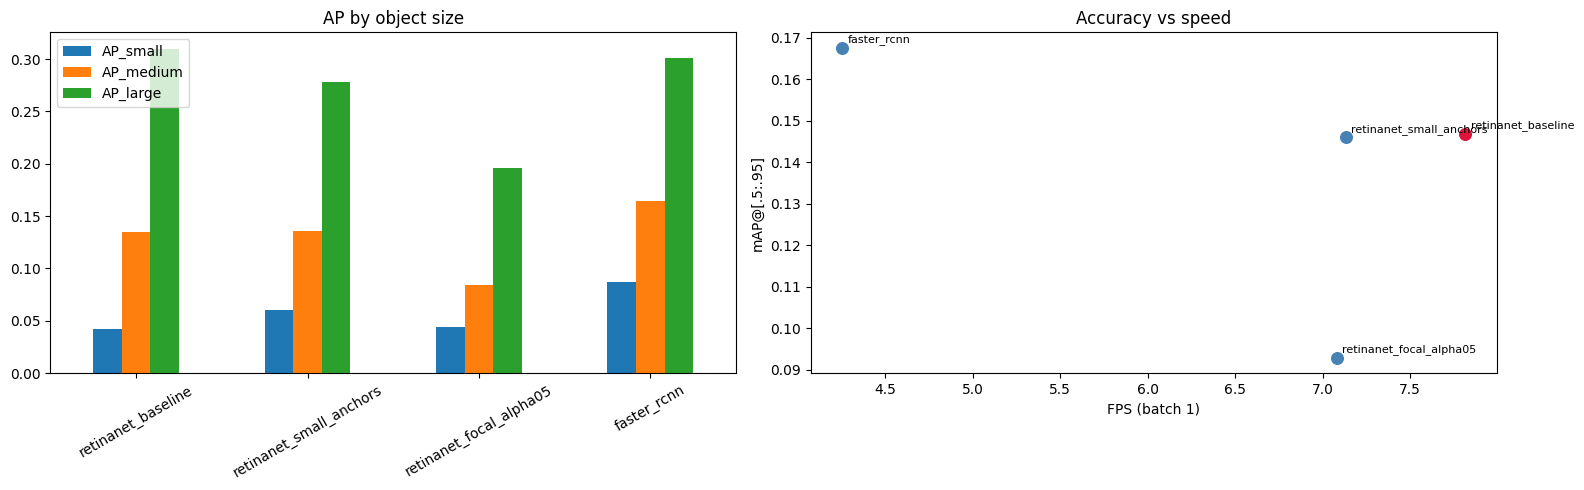

,retinanet_baseline,retinanet_small_anchors,retinanet_focal_alpha05,faster_rcnn
person,0.203,0.194,0.162,0.223
bicycle,0.131,0.140,0.066,0.196
car,0.346,0.343,0.298,0.378
van,0.177,0.174,0.059,0.200
truck,0.104,0.115,0.045,0.098
tricycle,0.107,0.091,0.045,0.110
bus,0.025,0.018,0.002,0.034
motor,0.082,0.093,0.067,0.103


In [20]:
summary = pd.DataFrame(RESULTS).T
cols = ["epochs", "train_images", "mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_small", "fps", "params_M"]
summary = summary[cols]
summary.insert(0, "role", ["initial" if n == "retinanet_baseline" else "best one-stage" if n == BEST else "two-stage" if n == "faster_rcnn" else "variant" for n in summary.index])
summary.insert(1, "budget", [RESULTS[n].get("budget", "") for n in summary.index])
summary["d_mAP vs baseline"] = summary["mAP"].astype(float) - float(RESULTS["retinanet_baseline"]["mAP"])
display(summary.astype({c: float for c in cols if c not in ("epochs", "train_images")}).round(4))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
plot_df = summary[["AP_small", "AP_medium", "AP_large"]].astype(float)
plot_df.plot.bar(ax=ax[0], rot=30, title="AP by object size"); ax[0].legend(loc="upper left")
for n, r in summary.iterrows():
    ax[1].scatter(float(r["fps"]), float(r["mAP"]), s=70, c="crimson" if n == BEST else "steelblue"); ax[1].annotate(n, (float(r["fps"]), float(r["mAP"])), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[1].set_xlabel("FPS (batch 1)"); ax[1].set_ylabel("mAP@[.5:.95]"); ax[1].set_title("Accuracy vs speed")
plt.tight_layout(); plt.show()

pc = pd.DataFrame({n: {c: RESULTS[n].get(f"AP_{c}") for c in CLASS_NAMES} for n in [*ONE_STAGE, *[k for k in RESULTS if k == "faster_rcnn"]]})
display(pc.astype(float).round(3))

In [21]:
# training loss per epoch: only for models trained in this notebook (section 6b); ready checkpoints have no log here
logs = [n for n in CFGS if (RUNS / n / "train.log").is_file()]
if not logs:
    print("No training logs: all compared models are ready checkpoints.")
else:
    fig, ax = plt.subplots(figsize=(8, 4))
    for name in logs:
        d = {int(e): float(l) for e, l in re.findall(r"epoch (\d+) done, mean loss ([\d.]+)", (RUNS / name / "train.log").read_text())}
        ax.plot(sorted(d), [d[k] for k in sorted(d)], marker="o", label=name, lw=2 if name == BEST else 1)
    ax.set_xlabel("epoch"); ax.set_ylabel("mean training loss"); ax.legend(fontsize=7); ax.set_title("Training loss (comparable only between runs with the same loss definition)")
    plt.tight_layout(); plt.show()

No training logs: all compared models are ready checkpoints.


## 11. Detection error analysis

Predictions with confidence scores of at least 0.3 are matched to ground truth using class-aware IoU matching at threshold 0.5. The analysis reports missed detections by object size and categorizes false positives. Selected frames illustrate dense, typical, and sparse scenes.

Evaluation metrics can be restored separately from per-frame prediction files. Visualizations requiring `pred_val.json` are skipped when the corresponding file is absent. The `REGENERATE_BEST_PREDICTIONS` setting enables regeneration by inference without training.


In [22]:
# Cached metrics do not imply that per-image detections are cached as well.
# To regenerate missing predictions for visualizations, set True below (GPU inference;
# it DOES NOT train a detector). Leave False for a fast, complete reporting run.
REGENERATE_BEST_PREDICTIONS = False

def pred_path(name):
    return RUNS / name / "pred_val.json"

def load_preds(name):
    path = pred_path(name)
    if not path.is_file():
        raise FileNotFoundError(
            f"Per-frame predictions for {name} are missing: {path}. "
            "The metrics cache alone does not contain bounding boxes."
        )
    return json.loads(path.read_text())

if REGENERATE_BEST_PREDICTIONS and BEST in RESULTS and not pred_path(BEST).is_file():
    print(f"Regenerating {BEST} predictions for visualization (no training) ...")
    model, device = load_one_stage(BEST)
    regenerated_metrics = evaluate_model(model, device, save_to=pred_path(BEST))
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"Predictions saved: {pred_path(BEST)}")
    print("Recomputed mAP:", regenerated_metrics.get("mAP"),
          "cached mAP:", RESULTS[BEST].get("mAP"))

for name in dict.fromkeys(n for n in ["retinanet_baseline", BEST, "faster_rcnn"] if n in RESULTS):
    if not pred_path(name).is_file():
        print(f"Skipping optional error breakdown for {name}: no pred_val.json (cached metrics are still valid).")
        continue
    rec, fp = error_breakdown(load_preds(name))
    print(f"=== {name} (score >= 0.3) ===")
    display(rec.round(3))
    print(fp.to_dict())


Skipping optional error breakdown for retinanet_baseline: no pred_val.json (cached metrics are still valid).
Skipping optional error breakdown for faster_rcnn: no pred_val.json (cached metrics are still valid).


In [23]:
def show_preds(name, image_ids, thr=0.3):
    preds = defaultdict(list)
    for p in load_preds(name):
        if p["score"] >= thr: preds[p["image_id"]].append(p)
    fig, axes = plt.subplots(1, len(image_ids), figsize=(8 * len(image_ids), 5.5))
    for ax, iid in zip(np.atleast_1d(axes), image_ids):
        ax.imshow(Image.open(du.image_path_for(DATA_ROOT / "val", VAL.imgs[iid]["file_name"]))); ax.axis("off")
        for a in VAL.loadAnns(VAL.getAnnIds(imgIds=iid)):
            x, y, w, h = a["bbox"]; ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="white" if a.get("iscrowd") else "lime", lw=1, ls="--" if a.get("iscrowd") else "-"))
        for p in preds[iid]:
            x, y, w, h = p["bbox"]; ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="red", lw=1))
        ax.set_title(f"{name} | frame {iid} | green=GT, red=pred, white dashed=ignored")
    plt.tight_layout(); plt.show()

counts = pd.Series({i: len(VAL.getAnnIds(imgIds=i, iscrowd=False)) for i in VAL_IDS})
chosen = [int(counts.idxmax()), int(counts.sub(counts.median()).abs().idxmin()), int(counts.idxmin() if counts.min() > 0 else counts[counts > 0].idxmin())]
# Visualizations are optional; metrics / tables remain usable without JSON detections.
visualization_name = next(
    (name for name in [BEST, "retinanet_baseline", "faster_rcnn"]
     if name in RESULTS and pred_path(name).is_file()),
    None,
)
if visualization_name is None:
    print("No per-frame prediction JSON found: skipping optional bounding-box plots.")
    print("To render the best RetinaNet predictions, set REGENERATE_BEST_PREDICTIONS=True in the previous cell.")
else:
    if visualization_name != BEST:
        print(f"Best model {BEST} has no prediction JSON. Plotting {visualization_name} instead.")
    show_preds(visualization_name, chosen)  # densest / median / sparsest frame

No per-frame prediction JSON found: skipping optional bounding-box plots.
To render the best RetinaNet predictions, set REGENERATE_BEST_PREDICTIONS=True in the previous cell.


## 12. Conclusions

- **Anchors grounded in data.** After resizing, the median box has sqrt(area) = 27 px and 25% of boxes are small. With default anchors (base 32), 92% of small ground-truth boxes have no anchor with IoU ≥ 0.5. Anchors starting at 16 px reduce this to 19.6% (all boxes: 32.1% → 4.9%).
- **Small anchors.** AP_small increases from 0.0423 to 0.0608 and AP50 from 0.2820 to 0.3159, but AP75 (0.1357 → 0.1166) and AP_large (0.3100 → 0.2780) decrease, so mAP@50:95 is unchanged (0.1468 vs 0.1460).
- **Focal α = 0.5** (mAP 0.0929) cannot be evaluated in isolation, since it also used step-20 sampling and 6 epochs.
- **Inference settings.** Raising `topk_candidates` to 2000 improves mAP to 0.1569 without retraining; NMS and score thresholds change it by less than 0.002.
- **One-stage vs two-stage.** Faster R-CNN reaches mAP 0.1675 and AP_small 0.0873 but runs at 4.3 FPS vs 7.8 FPS for RetinaNet (43.3M vs 36.5M parameters). It was trained on a smaller budget (step 20, 6 epochs), so the comparison is observational.
- **Limitations.** Single seed, unequal training budgets, IoU-threshold and NWD experiments not run.